# 43. RG3 최종 후보 — 가스 RF(기존) + 미성형 N1(unlabeled 정상 보강) 결합

| 역할 | 모델 | 근거 |
|---|---|---|
| 가스 | RF, 원값 21 + 새 변수 3개의 직전 10샷 std (labeled만) | 37번 반복 19 (8/17, 순열 p 0.007), 41번 M0 |
| 미성형 | 같은 변수 + **unlabeled 3,000샷을 정상으로 추가(가중치 0.3)** | 41번 N1 (시드 3개 모두 3/8, AP 3배) |
| 결합 | 검사 샷 K 중 g×K는 가스 모델 상위, 나머지는 미성형 모델 순위 | g = 0.68(불량 수 비율 17:8) / 0.5, 미리 정함 |

- 평가: Run 하나씩 빼고 검증(LORO), 시드 3개 평균·범위
- 검사 비율 0.5~30%별 불량·가스·미성형 개수, Precision, Recall, F1, 무작위 대비 배수
- 마지막 셀: 순열검정(재학습 포함)으로 우연 여부 확인 → 보고서 숫자로 쓰려면 꼭 돌리기

**준비**: 20a·20b 실행. 실행 시간: 본 실험 수 분, 순열검정 n=50이면 수십 분

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
import rg3_combo as RC
R = RC.run(seeds=(0, 1, 2))

RG3 평가 591샷 {'정상': 566, '가스': 17, '미성형': 8} | 변수 24개
  seed 0 완료
  seed 1 완료
  seed 2 완료


## 1. 검사 10%에서 비교 (기준: 기존 가스 모델만 = 가스 7~8/17, 미성형 1~2/8)

In [2]:
display(RC.at_rate(R, '10%').round(3))

,모델,검사 비율,검사_샷,불량(/25),가스(/17),가스_범위,미성형(/8),미성형_범위,Precision,Recall,F1,무작위대비,목표(가스≥7 & 미성형≥4)
0,가스 모델만,10%,60,9.333,7.667,7~8,1.667,1~2,0.156,0.373,0.220,3.677,-
1,결합 g=0.68,10%,60,9.000,6.000,5~7,3.000,3~3,0.150,0.360,0.212,3.546,-
2,결합 g=0.5,10%,60,9.333,6.000,6~6,3.333,3~4,0.156,0.373,0.220,3.677,-
3,미성형 모델만,10%,60,7.000,4.000,4~4,3.000,3~3,0.117,0.280,0.165,2.758,-


## 2. 다른 검사 비율 (5%, 20%)

In [3]:
display(RC.at_rate(R, '5%').round(3))
display(RC.at_rate(R, '20%').round(3))

,모델,검사 비율,검사_샷,불량(/25),가스(/17),가스_범위,미성형(/8),미성형_범위,Precision,Recall,F1,무작위대비,목표(가스≥7 & 미성형≥4)
0,가스 모델만,5%,30,5.667,4.333,4~5,1.333,1~2,0.189,0.227,0.206,4.465,-
1,결합 g=0.68,5%,30,3.333,1.000,1~1,2.333,2~3,0.111,0.133,0.121,2.627,-
2,결합 g=0.5,5%,30,3.000,1.000,1~1,2.000,1~3,0.100,0.120,0.109,2.364,-
3,미성형 모델만,5%,30,4.667,2.667,2~3,2.000,2~2,0.156,0.187,0.170,3.677,-


,모델,검사 비율,검사_샷,불량(/25),가스(/17),가스_범위,미성형(/8),미성형_범위,Precision,Recall,F1,무작위대비,목표(가스≥7 & 미성형≥4)
0,가스 모델만,20%,119,10.333,8.000,8~8,2.333,2~3,0.087,0.413,0.144,2.053,-
1,결합 g=0.68,20%,119,12.333,8.333,8~9,4.000,4~4,0.104,0.493,0.171,2.450,O
2,결합 g=0.5,20%,119,12.333,8.667,8~9,3.667,3~4,0.104,0.493,0.171,2.450,-
3,미성형 모델만,20%,119,11.667,8.000,8~8,3.667,3~4,0.098,0.467,0.162,2.318,-


## 3. 전체 표 (모델 × 검사 비율, 시드 평균)

In [4]:
display(R['summary'].round(3))

,모델,검사 비율,검사_샷,불량(/25),가스(/17),가스_범위,미성형(/8),미성형_범위,Precision,Recall,F1,무작위대비,목표(가스≥7 & 미성형≥4)
0,가스 모델만,0.5%,3,1.000,1.000,1~1,0.000,0~0,0.333,0.040,0.071,7.880,-
1,가스 모델만,1%,6,1.000,1.000,1~1,0.000,0~0,0.167,0.040,0.065,3.940,-
2,가스 모델만,2%,12,1.667,1.000,1~1,0.667,0~1,0.139,0.067,0.090,3.283,-
3,가스 모델만,3%,18,2.000,1.000,1~1,1.000,1~1,0.111,0.080,0.093,2.627,-
4,가스 모델만,5%,30,5.667,4.333,4~5,1.333,1~2,0.189,0.227,0.206,4.465,-
5,가스 모델만,7%,42,7.333,5.667,5~6,1.667,1~2,0.175,0.293,0.219,4.128,-
6,가스 모델만,10%,60,9.333,7.667,7~8,1.667,1~2,0.156,0.373,0.220,3.677,-
7,가스 모델만,15%,89,10.000,8.000,8~8,2.000,2~2,0.112,0.400,0.175,2.656,-
8,가스 모델만,20%,119,10.333,8.000,8~8,2.333,2~3,0.087,0.413,0.144,2.053,-
9,가스 모델만,30%,178,11.333,8.000,8~8,3.333,3~4,0.064,0.453,0.112,1.505,-


## 4. 모델별 AP (시드별)

In [5]:
display(R['ap'].round(3))

,seed,가스 모델 AP_가스,가스 모델 AP_미성형,미성형 모델 AP_미성형,미성형 모델 AP_가스
0,0,0.096,0.036,0.049,0.056
1,1,0.135,0.034,0.066,0.059
2,2,0.099,0.036,0.161,0.059


## 5. 검사 비율별 곡선

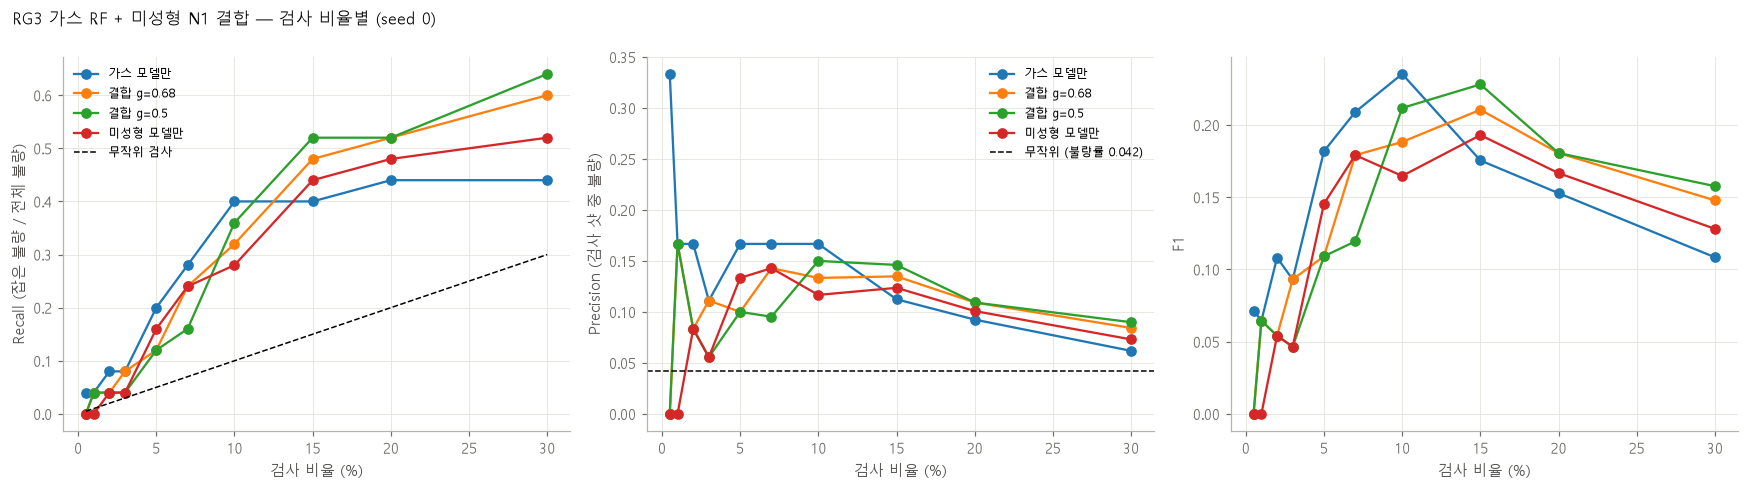

In [6]:
RC.plot(R, seed=0, save='./outputs/rg3_combo/curves.png')

## 6. 순열검정 (재학습 포함) — 보고서 숫자로 쓰려면 실행
라벨 위치를 Run 안에서 무작위로 옮기고 두 모델 학습·결합을 처음부터 반복 → 관측 포착 수가 우연을 넘는지 (p < 0.05)

In [7]:
P = RC.permutation_test(n=50, gas_share=0.68, rate=0.10)
display(P)

순열 0
순열 10


KeyboardInterrupt: 